# fundamental-pitch demo
Value one company with a DCF, stress the answer, and lay it out on one page. The company is **fictional** (`Example Industrial Co.`); every number is invented for teaching.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from quantskills.fundamental import (
    comps_table,
    dcf_value,
    example_case,
    implied_growth,
    plot_football_field,
    project,
    scenario_table,
    sensitivity,
    wacc,
)

case = example_case()
print(case.company.name, "| price", case.company.price, "| fictional:", case.company.fictional)

Example Industrial Co. | price 25.0 | fictional: True


## 1. The cash-flow build
FCFF = EBIT × (1 − tax) + D&A − capex − increase in working capital.

In [2]:
project(case).round(1)

,revenue,growth,ebit,ebit_margin,nopat,da,capex,delta_nwc,fcff
year,,,,,,,,,
1,2544.0,0.1,318.0,0.1,241.7,101.8,127.2,21.6,194.6
2,2683.9,0.1,348.9,0.1,265.2,107.4,134.2,21.0,217.3
3,2818.1,0.0,380.4,0.1,289.1,112.7,140.9,20.1,240.8
4,2944.9,0.0,412.3,0.1,313.3,117.8,147.2,19.0,264.9
5,3062.7,0.0,428.8,0.1,325.9,122.5,153.1,17.7,277.6


## 2. The DCF
WACC from CAPM and the after-tax cost of debt; Gordon-growth terminal value; mid-year discounting.

In [3]:
v = dcf_value(case)
print(
    f"WACC {wacc(case):.2%} | EV {v.enterprise_value:,.0f}m | {v.per_share:.2f}/share "
    f"({v.upside:+.0%} vs price) | terminal value = {v.terminal_share:.0%} of EV"
)

WACC 8.42% | EV 4,313m | 28.44/share (+14% vs price) | terminal value = 78% of EV


## 3. The terminal value dominates, so show the grid
One percentage point of WACC moves the value by roughly 20-25%.

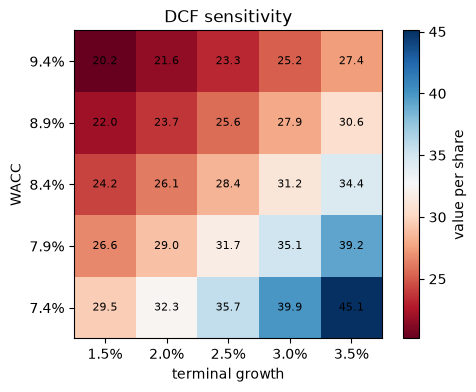

In [4]:
s = sensitivity(case)
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(s.to_numpy(), cmap="RdBu", origin="lower")
ax.set_xticks(range(5), [f"{g:.1%}" for g in s.columns])
ax.set_xlabel("terminal growth")
ax.set_yticks(range(5), [f"{r:.1%}" for r in s.index])
ax.set_ylabel("WACC")
for (i, j), val in pd.DataFrame(s.to_numpy()).stack().items():
    ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="value per share")
ax.set_title("DCF sensitivity");

## 4. Scenarios and the reverse DCF
The reverse DCF asks what the *market* already assumes: the revenue growth that makes the DCF equal the price.

In [5]:
display(scenario_table(case).round(3))
g = implied_growth(case)
print(
    f"price implies {g:.1%} growth a year; the base case assumes "
    f"{sum(case.forecast.revenue_growth) / case.forecast.years:.1%}"
)

,per_share,upside,wacc,terminal_growth,terminal_share
base,28.439,0.138,0.084,0.025,0.775
bear,13.849,-0.446,0.094,0.015,0.705
bull,43.475,0.739,0.079,0.030,0.813


price implies 1.9% growth a year; the base case assumes 5.0%


## 5. Peers and the football field

,peer,ev_ebitda,pe,value_ev_ebitda,value_pe
0,Peer A (fictional),8.5,15.0,22.23,25.08
1,Peer B (fictional),10.0,18.0,27.48,30.10
2,Peer C (fictional),9.2,16.5,24.68,27.59
3,Peer D (fictional),11.5,21.0,32.73,35.11
4,Peer E (fictional),7.8,13.0,19.78,21.74


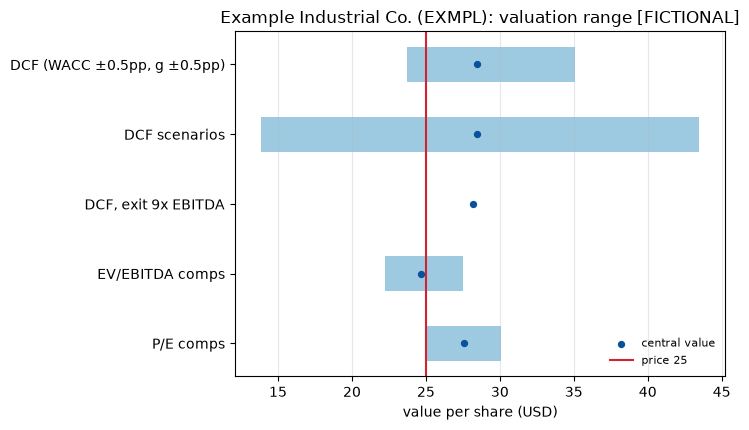

In [6]:
display(comps_table(case).round(2))
plot_football_field(case);

## Takeaways
- The answer is a **range**: scenarios span roughly 14 to 43 per share around a price of 25.
- Read the reverse DCF first: here the price needs only ~2% growth, below the base case's 5%.
- The pitch (`render_pitch`) lays out these numbers with *your* thesis; it never writes one.